In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
# A. PENGORGANISASIAN DATA
#Tabel Data
path = r"Adithia.xlsx"
dataraw = pd.read_excel(path)

print("  TABEL DATA NILAI MAHASISWA".center(62))
print(dataraw.to_string(index=False))
print()

# Tabel Frekuensi
urutan_grade = ["A+", "A", "B+", "B", "C", "F"]
datafrq = pd.crosstab(index=dataraw["Grade"], columns="Frekuensi")
datafrq = datafrq.reindex(urutan_grade, fill_value=0)
datafrq.columns.name = None

tabel_frq = datafrq.copy()
tabel_frq["Persentase (%)"] = (tabel_frq["Frekuensi"] / tabel_frq["Frekuensi"].sum() * 100).round(2)
tabel_frq.loc["Total"] = tabel_frq.sum()
tabel_frq["Frekuensi"] = tabel_frq["Frekuensi"].astype(int)

print("  TABEL FREKUENSI GRADE".center(62))
print(tabel_frq)
print()



                   TABEL DATA NILAI MAHASISWA                 
        ID               Nama  Nilai Kuis (100)  Nilai UTS (100)  Nilai UAS (100)  Nilai Akhir Grade
2455301006    Adithia Mustofa                85               88               68        80.04    AB
    120001           John Doe                85               78               90        84.44     A
    120005         Jane Smith                92               88               94        91.38     A
    120017    Michael Johnson                48               65               56        56.41     C
    120018        Emily Brown                90               85               88        87.65     A
    120022    Daniel Martinez                75               80               77        77.35    AB
    120024       Sarah Wilson                88               70               65        74.01     B
    120025       David Garcia                75               70               75        73.35     B
    120027        Jessica Le

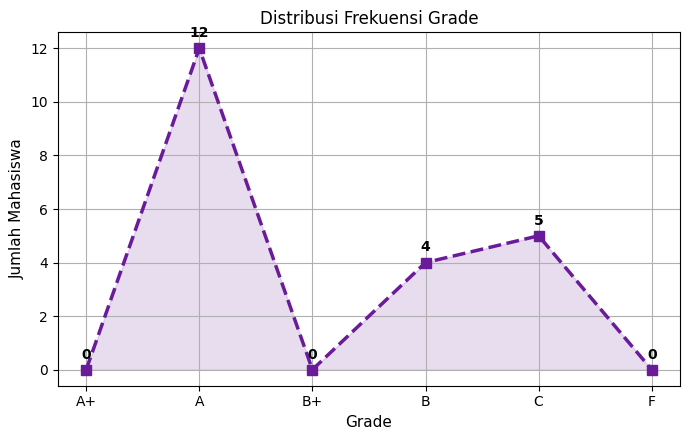

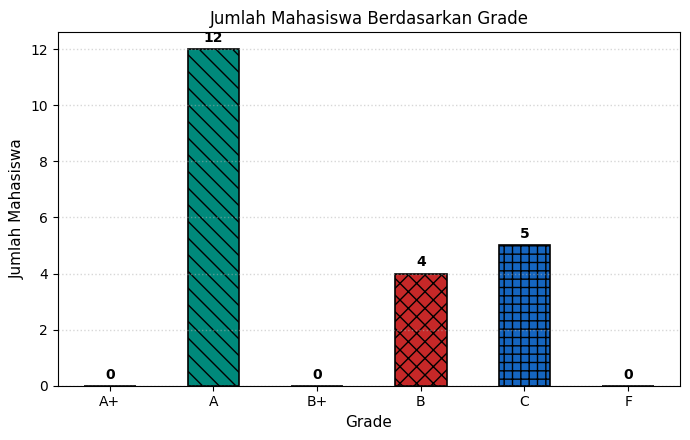

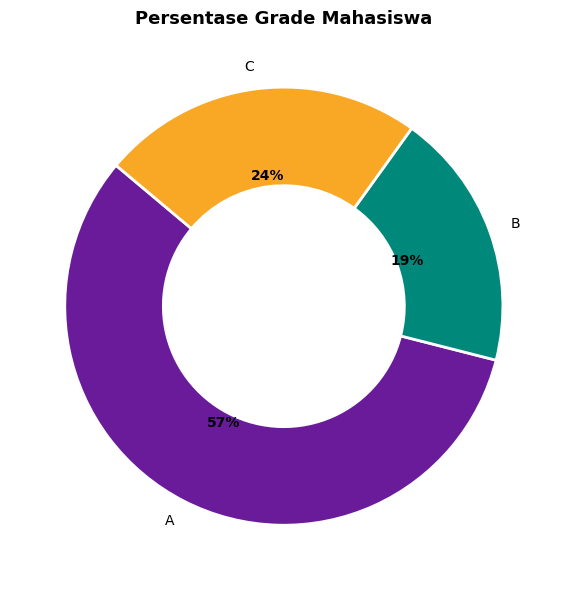

In [ ]:
# B. PENYAJIAN DATA

# Palet warna
warna_baru = ["#6A1B9A", "#00897B", "#F9A825", "#C62828", "#1565C0", "#8D6E63"]

# 1. GRAFIK GARIS
ax1 = datafrq.plot(
    kind="line",
    marker="s",
    color="#6A1B9A",
    linestyle="--",
    linewidth=2.5,
    markersize=7,
    figsize=(7, 4.5),
    grid=True,
    legend=False,
    title="Distribusi Frekuensi Grade"
)

ax1.set_xlabel("Grade", fontsize=11)
ax1.set_ylabel("Jumlah Mahasiswa", fontsize=11)

ax1.set_xticks(range(len(datafrq)))
ax1.set_xticklabels(datafrq.index)

# Memberikan area transparan di bawah garis
ax1.fill_between(
    range(len(datafrq)),
    datafrq["Frekuensi"],
    alpha=0.15,
    color="#6A1B9A"
)

# Menampilkan nilai pada setiap titik
for i, v in enumerate(datafrq["Frekuensi"]):
    ax1.annotate(
        str(v),
        (i, v),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax1.figure.tight_layout()
ax1.figure.savefig("grafik_garis_baru.png", dpi=150)
ax1.figure.show()


# 2. GRAFIK BATANG
ax2 = datafrq.plot(
    kind="bar",
    y="Frekuensi",
    rot=0,
    figsize=(7, 4.5),
    legend=False,
    title="Jumlah Mahasiswa Berdasarkan Grade"
)

# Memberikan warna dan pola berbeda pada setiap batang
pola = ["//", "\\\\", "..", "xx", "++", "oo"]

for batang, w, p in zip(ax2.patches, warna_baru, pola):
    batang.set_facecolor(w)
    batang.set_edgecolor("black")
    batang.set_hatch(p)
    batang.set_linewidth(1.2)

ax2.set_xlabel("Grade", fontsize=11)
ax2.set_ylabel("Jumlah Mahasiswa", fontsize=11)

# Grid horizontal
ax2.grid(
    axis="y",
    linestyle=":",
    linewidth=1,
    alpha=0.5
)

# Nilai di atas batang
for i, v in enumerate(datafrq["Frekuensi"]):
    ax2.text(
        i,
        v + 0.15,
        str(v),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax2.figure.tight_layout()
ax2.figure.savefig("grafik_batang_baru.png", dpi=150)
ax2.figure.show()


# 3. DONUT CHART
data_pie = datafrq[datafrq["Frekuensi"] > 0]

fig, ax3 = plt.subplots(figsize=(6, 6))

wedges, texts, autotexts = ax3.pie(
    data_pie["Frekuensi"],
    labels=data_pie.index,
    autopct="%1.0f%%",
    startangle=140,
    colors=warna_baru[:len(data_pie)],
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2,
        "width": 0.45
    },
    textprops={
        "fontsize": 10
    }
)

# Membuat persentase lebih tebal
for autotext in autotexts:
    autotext.set_fontweight("bold")
    autotext.set_color("black")

ax3.set_title(
    "Persentase Grade Mahasiswa",
    fontsize=13,
    fontweight="bold"
)

ax3.set_ylabel("")

ax3.figure.tight_layout()
ax3.figure.savefig("donut_chart_baru.png", dpi=150)
ax3.figure.show()

In [ ]:
# C. STATISTIKA DESKRIPTIF
dataraw["Nilai Akhir"] = pd.to_numeric(dataraw["Nilai Akhir"], errors="coerce")
dt = dataraw["Nilai Akhir"]
stats = dt.describe()
stats["Standard Error"] = dt.sem()
stats["Median"] = dt.median()
stats["Mode"] = dt.mode().iloc[0]
stats["variance"] = dt.var()
stats["range"] = dt.max() - dt.min()
stats["skewness"] = dt.skew()
stats["kurtosis"] = dt.kurtosis()

print("  STATISTIKA DESKRIPTIF NILAI AKHIR".center(62))
print(stats.round(4).to_string())
print()

# Tambahan: IQR dan deteksi outlier (metode 1,5 x IQR)
q1, q3 = dt.quantile(0.25), dt.quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr
outlier = dataraw[(dt < batas_bawah) | (dt > batas_atas)]

print("  IQR DAN DETEKSI OUTLIER (1,5 x IQR)".center(62))
print(f"Q1            : {q1:.2f}")
print(f"Q3            : {q3:.2f}")
print(f"IQR           : {iqr:.2f}")
print(f"Batas bawah   : {batas_bawah:.2f}")
print(f"Batas atas    : {batas_atas:.2f}")
print(f"Nilai modus   : {dt.mode().tolist()}")
print(f"Koef. variasi : {dt.std() / dt.mean() * 100:.2f}%")
if outlier.empty:
    print("Outlier       : tidak ada")
else:
    print("Outlier       :")
    print(outlier[["NIM", "Nama", "Nilai"]].to_string(index=False))

               STATISTIKA DESKRIPTIF NILAI AKHIR              
count              31.0000
mean               76.3445
std                13.2580
min                46.0100
25%                68.8000
50%                79.3000
75%                86.7900
max                94.0300
Standard Error      2.3812
Median             79.3000
Mode               77.3000
variance          175.7744
range              48.0200
skewness           -0.7002
kurtosis           -0.4245

              IQR DAN DETEKSI OUTLIER (1,5 x IQR)             
Q1            : 68.80
Q3            : 86.79
IQR           : 17.99
Batas bawah   : 41.82
Batas atas    : 113.77
Nilai modus   : [77.3, 80.3]
Koef. variasi : 17.37%
Outlier       : tidak ada
